# SIT307 - 11.1 High Distinction Task Machine Learning Research

In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix, roc_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

In [120]:
# load dataset
df = pd.read_csv('heart.csv')

# inspect dataset dimensions
print("Dataset Shape:", df.shape)

# check missing values
print("Missing values per column:\n", df.isnull().sum())

# features X and target label y
X = df.drop('target', axis=1)
y = df['target']

# split train:test 80:20 ratio
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# standardize numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# convert to dataframe
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

base_models = {"Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
               "Naive Bayes": GaussianNB(),
               "K-Nearest Neighbors": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
               "Decision Tree": DecisionTreeClassifier(random_state=42),
               "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
               "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42)}

Dataset Shape: (1025, 14)
Missing values per column:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [121]:
# impute missing values using Linear Regression
def linear_regression_impute(data: pd.DataFrame) -> pd.DataFrame:
    df_imp = data.copy()
    
    # return if no missing values
    if df_imp.isnull().sum().sum() == 0:
        return df_imp
        
    for col in df_imp.columns:
        if df_imp[col].isnull().sum() > 0:
            # calculate absolute correlations with the target column
            corr = df_imp.corr()[col].abs().sort_values(ascending=False)
            
            best_corr_col = None
            for candidate in corr.index[1:]:  # Skip the self-correlation entry
                if df_imp[candidate].isnull().sum() == 0:
                    best_corr_col = candidate
                    break
            
            # train linear regression on complete rows and predict missing values
            if best_corr_col:
                known = df_imp[df_imp[col].notnull()]
                unknown = df_imp[df_imp[col].isnull()]
                
                lr = LinearRegression()
                lr.fit(known[[best_corr_col]], known[col])
                predicted_values = lr.predict(unknown[[best_corr_col]])
                
                df_imp.loc[df_imp[col].isnull(), col] = predicted_values
    return df_imp

#evaluate a classifier, returning key classification metrics (Accuracy, Precision, Recall, Specificity, F1-Score, AUC, and MCC)
def evaluate_model(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else y_pred
    
    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, zero_division=0)
    rec = recall_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred)
    auc = roc_auc_score(y_te, y_proba)
    mcc = matthews_corrcoef(y_te, y_pred)
    
    cm = confusion_matrix(y_te, y_pred)
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    sensitivity = tp / (tp + fn) if (tn + fp) > 0 else 0
    
    metrics = {"Accuracy": acc,
               "Precision": prec,
               "Recall": rec,
               "Specificity": spec,
               "F1-Score": f1,
               "AUC": auc,
               "Sensitivity": sensitivity,
               "MCC": mcc}
    return metrics, y_pred, y_proba

In [125]:
results = {}
predictions = {}
probabilities = {}

# train and evaluate baseline models
for name, model in base_models.items():
    metrics, y_pred, y_proba = evaluate_model(model, X_train_scaled, y_train, X_test_scaled, y_test)
    results[name] = metrics
    predictions[name] = y_pred
    probabilities[name] = y_proba
        
# define estimators for Stacking Ensemble
estimators = [('lr', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))),
              ('nb', GaussianNB()),
              ('knn', make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, metric='euclidean'))),
              ('dt', DecisionTreeClassifier(criterion='entropy', random_state=42)),
              ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
              ('xgb', XGBClassifier(eval_metric='logloss', random_state=42))]
    
cv_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
stacked_model = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(random_state=42), cv=cv_fold)

# Stacking Classifier with Logistic Regression
stacked_metrics, stacked_pred, stacked_proba = evaluate_model(stacked_model, X_train_scaled, y_train, X_test_scaled, y_test)
    
results["Proposed Stacking Ensemble"] = stacked_metrics
predictions["Proposed Stacking Ensemble"] = stacked_pred
probabilities["Proposed Stacking Ensemble"] = stacked_proba
    
# summary table
results_df = pd.DataFrame(results).T
    
print("Result summary table:")
print(results_df[["Accuracy", "F1-Score", "Recall", "Precision", "Sensitivity", "Specificity", "MCC", "AUC"]].round(4))

Result summary table:
                            Accuracy  F1-Score  Recall  Precision  \
Logistic Regression           0.7951    0.8108  0.8738     0.7563   
Naive Bayes                   0.8000    0.8178  0.8932     0.7541   
K-Nearest Neighbors           0.8341    0.8440  0.8932     0.8000   
Decision Tree                 0.9854    0.9852  0.9709     1.0000   
Random Forest                 0.9854    0.9852  0.9709     1.0000   
XGBoost                       0.9854    0.9852  0.9709     1.0000   
Proposed Stacking Ensemble    0.9854    0.9852  0.9709     1.0000   

                            Sensitivity  Specificity     MCC     AUC  
Logistic Regression              0.8738       0.7157  0.5973  0.8787  
Naive Bayes                      0.8932       0.7059  0.6102  0.8706  
K-Nearest Neighbors              0.8932       0.7745  0.6727  0.9486  
Decision Tree                    0.9709       1.0000  0.9712  0.9854  
Random Forest                    0.9709       1.0000  0.9712  1.0000  

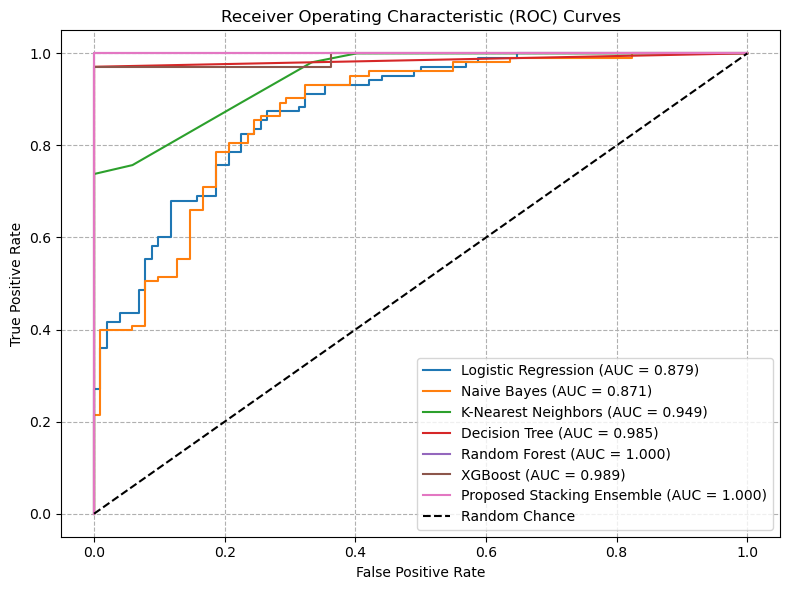

In [126]:
plt.figure(figsize=(8, 6))
for name, y_proba in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_val = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend()
plt.grid(True, linestyle="--")
plt.tight_layout()
plt.show()

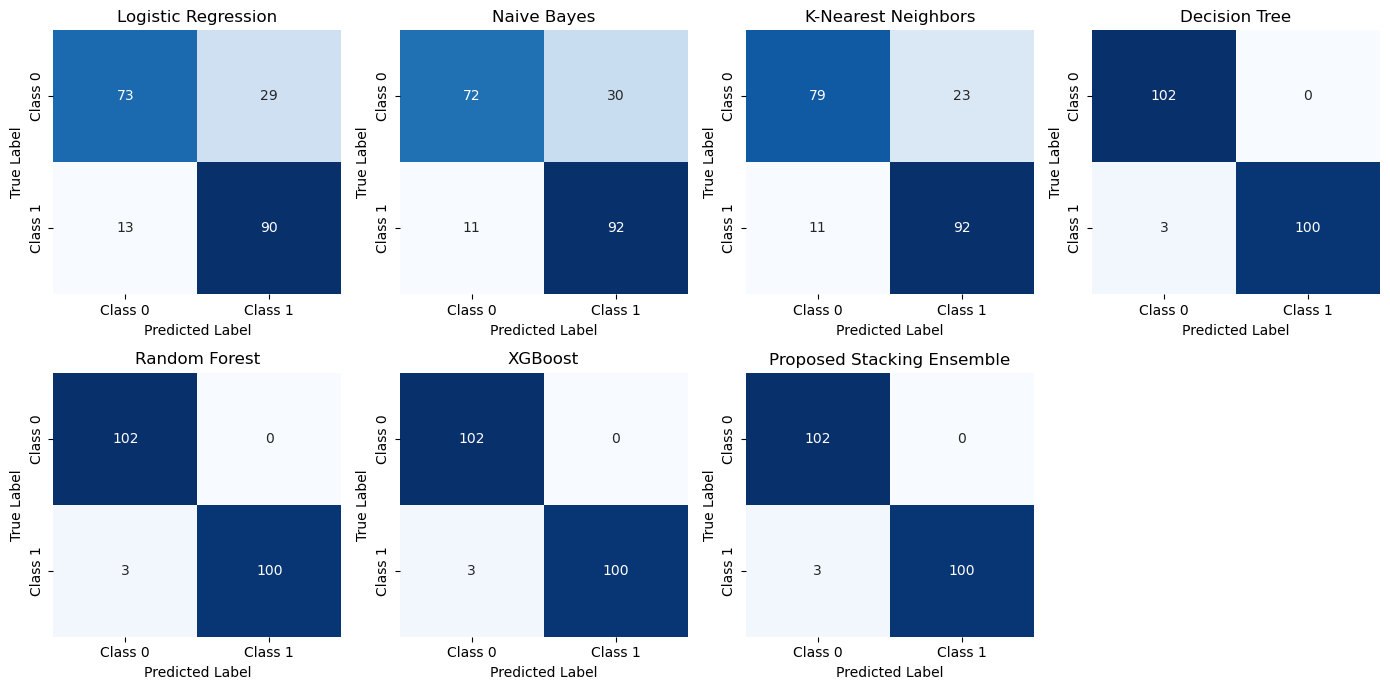

In [129]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Class 0', 'Class 1'], 
                yticklabels=['Class 0', 'Class 1'])
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')
    axes[idx].set_title(name)

# Hide any empty subplots (e.g., the 8th plot slot)
for j in range(len(predictions), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()